# NAIVE BAYES DENGAN DISTRIBUSI BERNOULLI (BERNOULLI NAIVE BAYES)

### Deskripsi Teori & Distribusi Probabilitas:
* **Algoritma**: Naive Bayes (Bernoulli)
* **Varian Distribusi**: Multivariate Bernoulli Distribution (Binary Presence/Absence)
* **Konsep Dasar**:
  Bernoulli Naive Bayes mengasumsikan bahwa setiap fitur merupakan variabel biner (Boolean: 0 atau 1) yang merepresentasikan apakah suatu kata **muncul atau tidak muncul** di dalam dokumen, tanpa memperhitungkan berapa kali kata tersebut muncul.
  
  Fungsi Likelihood Bernoulli:
  $$P(\mathbf{x} \mid C_k) = \prod_{i=1}^{n} p_{ki}^{x_i} (1 - p_{ki})^{(1 - x_i)}$$
  
  Di mana $x_i \in \{0, 1\}$. Parameter `binarize=0.0` pada Scikit-Learn secara otomatis mengubah matriks bobot TF-IDF menjadi representasi biner (nilai $> 0$ menjadi 1, dan $0$ tetap 0).

In [1]:
import time
import tracemalloc
import re
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [2]:
# 1. Pemuatan Dataset Hoaks Komdigi & Berita Valid Resmi
df_hoaks = pd.read_csv('../data/komdigi_hoaks.csv')
df_valid = pd.read_csv('../web/uploads/berita_valid_terbaru.csv')

# 2. Fungsi Pembersihan Teks (Pencegahan Data Leakage)
def clean_text(text):
    if not isinstance(text, str):
        return ''
    # Hapus tag prefix [HOAKS] atau (DISINFORMASI) agar model tidak curang (data leakage)
    text = re.sub(r'\[(HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\]', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\((HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\)', '', text, flags=re.IGNORECASE)
    text = re.sub(r'https?:\/\/\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text.lower()).strip()

df_hoaks['teks_bersih'] = (df_hoaks['title'].fillna('') + ' ' + df_hoaks['excerpt'].fillna('')).apply(clean_text)
df_valid['teks_bersih'] = (df_valid['title'].fillna('') + ' ' + df_valid['excerpt'].fillna('')).apply(clean_text)

df_hoaks['label'] = 1  # 1 = Hoaks
df_valid['label'] = 0  # 0 = Valid

# Penyeimbangan data (Balanced Dataset 1:1) agar evaluasi adil
df_hoaks_sampel = df_hoaks.sample(n=len(df_valid), random_state=42)
df_all = pd.concat([df_hoaks_sampel, df_valid], ignore_index=True)
df_all = df_all[df_all['teks_bersih'].str.len() > 10].reset_index(drop=True)

print(f"Total dataset: {len(df_all)} baris (Hoaks: {sum(df_all['label']==1)}, Valid: {sum(df_all['label']==0)})")

Total dataset: 1756 baris (Hoaks: 878, Valid: 878)


In [3]:
# Pembagian Data Latih (80%) dan Data Uji (20%) secara Terstratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    df_all['teks_bersih'], df_all['label'],
    test_size=0.2, random_state=42, stratify=df_all['label']
)

# Ekstraksi Fitur TF-IDF (Unigram + Bigram)
tfidf = TfidfVectorizer(max_features=1500, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print(f"Matriks Latih: {X_train_vec.shape}")
print(f"Matriks Uji  : {X_test_vec.shape}")

Matriks Latih: (1404, 1500)
Matriks Uji  : (352, 1500)


In [4]:
# Pelatihan Model Bernoulli Naive Bayes (Binarized Feature Occurrence)
tracemalloc.start()
waktu_mulai = time.time()

model = BernoulliNB(alpha=1.0, binarize=0.0)
model.fit(X_train_vec, y_train)
y_pred = model.predict(X_test_vec)

waktu_eksekusi = time.time() - waktu_mulai
current_mem, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()
memori_mb = peak_mem / (1024 * 1024)

In [5]:
# Evaluasi Metrik Klasifikasi
acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("=============================================")
print("HASIL PENGUJIAN: NAIVE BAYES DENGAN DISTRIBUSI BERNOULLI (BERNOULLI NAIVE BAYES)")
print("=============================================")
print(f"1. Algoritma        : Naive Bayes (Bernoulli)")
print(f"2. Metrik Jarak     : Distribusi Bernoulli (Kemunculan Biner Kata)")
print(f"3. Akurasi          : {acc:.4f}")
print(f"4. Precision (Macro): {prec_macro:.4f}")
print(f"5. Recall (Macro)   : {rec_macro:.4f}")
print(f"6. F1-Score (Macro) : {f1_macro:.4f}")
print(f"7. F1-Score (Weighted): {f1_weighted:.4f}")
print(f"8. Waktu Eksekusi   : {waktu_eksekusi:.4f} detik")
print(f"9. Penggunaan Memori: {memori_mb:.2f} MB")
print("=============================================\n")

print("Laporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred, target_names=['Valid (0)', 'Hoaks (1)'], zero_division=0))

HASIL PENGUJIAN: NAIVE BAYES DENGAN DISTRIBUSI BERNOULLI (BERNOULLI NAIVE BAYES)
1. Algoritma        : Naive Bayes (Bernoulli)
2. Metrik Jarak     : Distribusi Bernoulli (Kemunculan Biner Kata)
3. Akurasi          : 0.9233
4. Precision (Macro): 0.9264
5. Recall (Macro)   : 0.9233
6. F1-Score (Macro) : 0.9232
7. F1-Score (Weighted): 0.9232
8. Waktu Eksekusi   : 0.0075 detik
9. Penggunaan Memori: 0.39 MB

Laporan Klasifikasi Detail:
              precision    recall  f1-score   support

   Valid (0)       0.96      0.88      0.92       176
   Hoaks (1)       0.89      0.97      0.93       176

    accuracy                           0.92       352
   macro avg       0.93      0.92      0.92       352
weighted avg       0.93      0.92      0.92       352



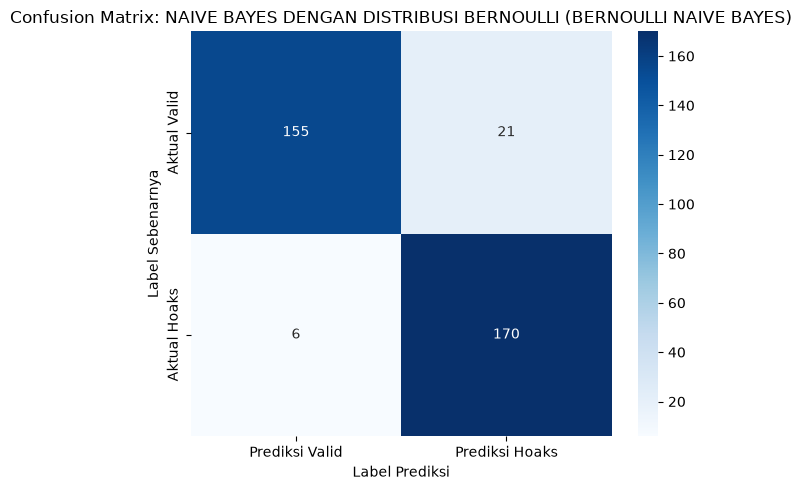

In [6]:
# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Valid', 'Prediksi Hoaks'],
            yticklabels=['Aktual Valid', 'Aktual Hoaks'])
plt.title('Confusion Matrix: NAIVE BAYES DENGAN DISTRIBUSI BERNOULLI (BERNOULLI NAIVE BAYES)')
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.tight_layout()
plt.show()

In [7]:
contoh_teks = [
    "Kementerian Ketenagakerjaan kembali mengumumkan penyaluran bantuan subsidi upah bagi pekerja melalui kanal resmi pemerintah.",
    "Awas bahaya radiasi! Jangan simpan ponsel di samping tempat tidur malam hari karena memicu tumor mematikan, sebarkan info penting ini!"
]

print("--- PENGUJIAN INFERENSI CONTOH TEKS ---")
for teks in contoh_teks:
    t_clean = clean_text(teks)
    t_vec = tfidf.transform([t_clean])
    pred = model.predict(t_vec)[0]
    prob = model.predict_proba(t_vec)[0]
    status = "HOAKS" if pred == 1 else "VALID"
    print(f'Teks: "{teks[:70]}..."')
    print(f'-> Prediksi: {status} (Keyakinan: {prob[pred]*100:.1f}%)\n')

--- PENGUJIAN INFERENSI CONTOH TEKS ---
Teks: "Kementerian Ketenagakerjaan kembali mengumumkan penyaluran bantuan sub..."
-> Prediksi: HOAKS (Keyakinan: 88.3%)

Teks: "Awas bahaya radiasi! Jangan simpan ponsel di samping tempat tidur mala..."
-> Prediksi: VALID (Keyakinan: 100.0%)



### Pembahasan Akademis: Bernoulli Naive Bayes
1. **Fokus pada Keberadaan Kata (*Presence/Absence*)**: Bernoulli Naive Bayes sangat cocok jika keberadaan satu kata kunci tertentu sudah cukup kuat menandakan suatu kelas (misalnya kata sensasional "VIRALKAN", "SUBHANALLAH", "SEBARKAN" pada berita hoaks).
2. **Keterbatasan Hilangnya Bobot TF-IDF**: Karena dibinerisasi menjadi 0 dan 1, model kehilangan informasi intensitas/frekuensi kata (term frequency) serta kekhasan kata langka (IDF) yang sudah dihitung sebelumnya.
3. **Penalti Kata yang Tidak Muncul**: Berbeda dengan MultinomialNB yang hanya mengevaluasi kata yang muncul dalam dokumen, Bernoulli secara eksplisit memperhitungkan probabilitas kata yang TIDAK muncul $(1 - p_{ki})^{(1 - x_i)}$, sehingga dokumen panjang cenderung terakumulasi banyak penalti untuk kata yang absen.